In [1]:
from dotenv import load_dotenv

load_dotenv()

True

## 匯入 trace 到 LangSmith

從你存放專案的工作目錄進入 `traces` 資料夾, 之後安裝相依套件:

```bash
cd lca-langsmith-essentials/langgraph-agent/traces
uv sync --upgrade
```

註: 我們使用專案根目錄下的 `.env` 來設定環境變數。

開啟 terminal
在 trace 資料夾，將以下指令中的 `001` 替換成你要的流水號(0,1,2, ...)，並執行以下指令：

```bash
cd langgraph-agent/traces
uv run python upload_traces.py \
--input traces-1.json \
--project langslice-traces-1-001
```

本份資料包含 **215 個 Run、13 個 Trace、10 個 Thread**。

```
(.venv) hychen39@Hungs-MacBook-Pro-2 lca-langsmith-essentials % cd langgraph-agent/traces
(.venv) hychen39@Hungs-MacBook-Pro-2 traces % uv run python upload_traces.py \
> --input traces-1.json \
> --project langslice-traces-1-001
warning: `VIRTUAL_ENV=/Users/hychen39/0work2/LangChain_Academy/lca-langsmith-essentials/.venv` does not match the project environment path `.venv` and will be ignored; use `--active` to target the active environment instead
Loaded 215 runs from traces-1.json
Spread 13 traces across 10 threads over 0.95 days: 2026-11-24 10:41 to 2026-11-25 08:15
Uploading 13 traces to project 'langslice-traces-1-001'...
  Uploaded 10/13 traces
Flushing...
Verified 215/215 runs landed.
Done! Uploaded 13 traces across 10 threads to 'langslice-traces-1-001'.
```

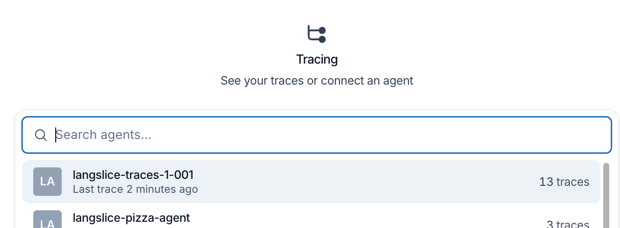

## 將 Trace 轉換成 Example

1. 在 tracing project 切換到 **Thread** 檢視。
2. 將搜尋列左側的比對範圍設為 **`in any run`**。

在左則 Shortcuts Panel 中，勾選 `add_pizza_to_order` 的 Run Name.

勾選所有的 Threads，並點擊下方的 **Add to Dataset** 按鈕，將這些 Trace 轉換成 Example。

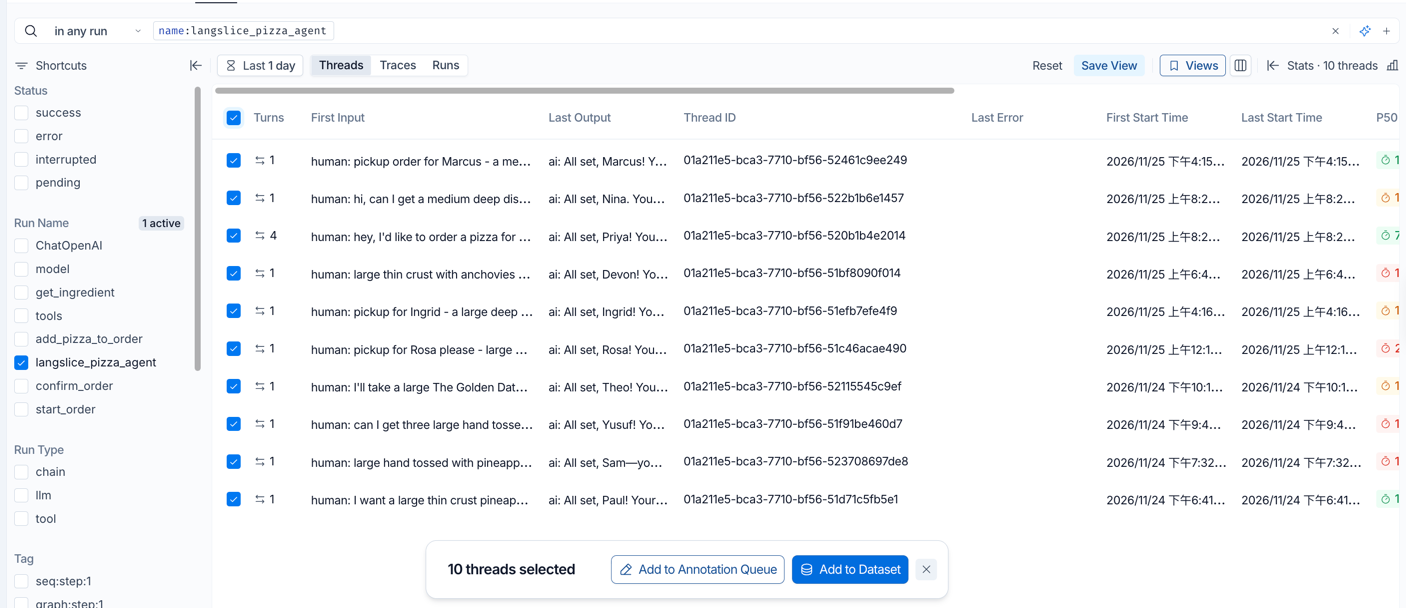

按 **New Dataset**，建立你的dataset。
例如: `pizza_order_001`

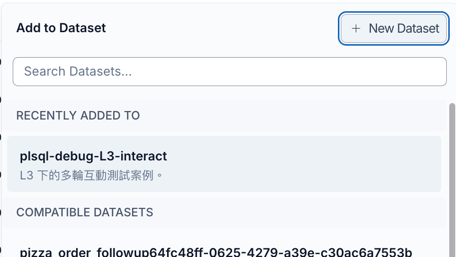

## 建立 code evaluator

In [2]:
"""Code evaluator for out-of-stock ingredients in pizza orders."""

import json

import database as db
from langsmith.schemas import Run, Example


def ingredient_stock_evaluator(run: Run, example:Example=None):
    # 取得 run 的 outputs
    outputs = run.outputs if hasattr(run, "outputs") else run.get("outputs", {})
    outputs = outputs or {}
    # 反向遍歷 messages，找到最近一則含 order 的 ToolMessage
    for message in reversed(outputs.get("messages", [])):
        if isinstance(message, dict):
            role = message.get("role") or message.get("type")
            content = message.get("content")
        else:
            role = message.type
            content = message.content

        if role != "tool":
            continue

        # 轉換成 json dict
        result = json.loads(content)
        # 取出 order
        order = result.get("order")
        if not order:
            continue

        # 產生缺貨配料集合 (使用 Set - 避免重複)
        # 使用 py 的生成式(Comprehension) 語法
        out_of_stock = {
            topping
            for pizza in order["pizzas"]
            for topping in pizza["toppings"]
            if db.get_ingredient(topping)["stock_units"] <= 0
        }

        # 回傳: 分數、及說明
        return {
            "score": 0 if out_of_stock else 1,
            "comment": (
                f"Out-of-stock ingredients added: {', '.join(sorted(out_of_stock))}"
                if out_of_stock
                else "All ordered ingredients are in stock."
            ),
        }

    return {
        "key": "ingredient_stock",
        "score": 1,
        "comment": "No order found.",
    }

## 建立 evaluation target

In [3]:
import uuid

from langchain.messages import AIMessage, HumanMessage

from agent import GREETING, pizza_agent

def evaluation_target(inputs: dict) -> dict:
    history = [AIMessage(content=GREETING)]
    thread_id = f"eval-{uuid.uuid4()}"

    # 產生 Initital State for the agent (Initial conversation history)
    for message in inputs.get("messages", []):
        # Examples created from LangSmith traces use LangChain's serialized
        # message shape (``type=human``), while hand-authored examples often
        # use the OpenAI shape (``role=user``). Accept both.
        message_type = message.get("role") or message.get("type")
        if message_type not in {"user", "human"}:
            continue

        history.append(HumanMessage(content=message["content"]))

        # Invoke your pizza agent
        # 需要有 API Key 才能使用 langchain 的 agent.invoke()
        result = pizza_agent.invoke(
            {"messages": history},
            config={"configurable": {"thread_id": thread_id}},
        )
        history = result["messages"]

    return {"messages": history}


## 執行實驗

In [5]:
from langsmith import Client
client = Client()

dataset_name = "pizza_order_001"  # dataset_name 是先前 trace 轉換成的 dataset 名稱

results = client.evaluate(
    evaluation_target,
    data=dataset_name,
    evaluators=[ingredient_stock_evaluator],
    experiment_prefix="stock-baseline",
)

View the evaluation results for experiment: 'stock-baseline-cefb22fc' at:
https://smith.langchain.com/o/0de765cc-4ea8-5d01-ae23-81aac46d1d30/datasets/cc47dd20-734b-4076-814b-8007304b6b45/compare?selectedSessions=c4583f71-c9aa-4f32-8eb8-7b41387fd43f




0it [00:00, ?it/s]

In [11]:
from langsmith import EvaluationResult
# Print the evaluation results
from langsmith.schemas import ExperimentResults


# Print the evaluation results
def print_eval_result(eval_result: ExperimentResults):
    for item in eval_result._results:
        run = item["run"]
        example = item["example"]
        results:EvaluationResult = item["evaluation_results"]["results"]
        metadata = example.metadata or {}

        for result in results:
            formatted_output = f"""
* Case ID: {metadata.get("case_id", "未提供")}
* 問題：{example.inputs}
* 參考答案：{example.outputs}
* Agent 回答：{run.outputs}
* 評分項目：{result.key}
* 分數：{result.score}
* 評分理由：{result.comment}
============
"""
        print(formatted_output)

In [12]:
print_eval_result(results)


* Case ID: 未提供
* 問題：{'messages': [{'role': 'system', 'content': 'You are Sal, the ordering assistant for LangSlice, a pizzeria in Brooklyn, NY.\nYou chat with customers to answer questions about the shop and to take their pizza orders.\n\n## Answering questions\n\nUse `search_company_info` for anything about the business itself: address, hours,\nphone number, delivery radius and fees, payment methods, allergens, catering,\nrewards. Do not answer these from memory - look them up, then answer in your own\nwords. Use `get_menu` for sizes, crusts, specialty pizzas, toppings, and sides.\nWhen the customer asks to see the full menu, return the tool\'s `display_markdown`\nverbatim. It is deliberately formatted to render cleanly in both the chat UI and\na plain terminal. For a question about only one part of the menu, answer just\nthat part instead of printing the full menu.\n\n## Recommending something\n\nWhen a customer asks what you would recommend, call `get_menu` and recommend from\nwhat